In [1]:
# Samarth Sharma | samarth.011@nmims.in
# Few-shot bearing fault diagnosis using MAML
# Paper: Zhang et al., https://arxiv.org/abs/2007.12851
# Set DATASET_PATH below and run the cells in order.

import csv
import hashlib
import json
import os
import platform
import random
import re
import time
import urllib.request
from collections import OrderedDict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.func import functional_call
from scipy.io import loadmat
from scipy.signal import resample_poly
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from IPython.display import display, Markdown, Image

# Locate the project when Jupyter starts in the project folder or src/.
current_folder = Path.cwd().resolve()
possible_folders = [current_folder, *current_folder.parents,
                    current_folder / "MAML_Bearing_Reproduction"]
ROOT = current_folder
for folder in possible_folders:
    if (folder / "src" / "MAML_Bearing_Reproduction.ipynb").exists():
        ROOT = folder
        break
os.chdir(ROOT)
RESULTS = ROOT / "results"

# Set the folder containing the .mat files.
DATASET_PATH = os.environ.get("CWRU_DATASET_PATH", str(ROOT.parent / "CWRU_raw"))
SEEDS = [1, 2, 3]
RERUN_TRAINING = False  # True retrains; False validates and reuses completed runs.
DOWNLOAD_DATA = False  # Optional official download; manual setup: data/README.md.
print("Dataset:", DATASET_PATH)
print("Results:", RESULTS)
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())


FAST_DEBUG = False


# Settings shared by the two experiments.
@dataclass
class Config:
    ways: int = 3
    shots: int = 5
    train_queries: int = 4  # 5 support + 4 query = paper's 9 training samples/class
    queries: int = 15
    train_samples_per_class: int = 9
    inner_lr: float = 0.01
    outer_lr: float = 0.001  # assumption: not specified in paper
    inner_steps: int = 1
    learn_inner_lr: bool = True
    meta_batch_size: int = 1  # practical CPU budget; paper: 25
    iterations: int = 100  # practical CPU budget; paper: 1500
    eval_tasks: int = 30
    seed: int = 1
    threads: int = 2
    device: str = 'cpu'
    dataset_path: str = DATASET_PATH
    results_path: str = str(ROOT / 'results')
    fast_debug: bool = FAST_DEBUG

    @property
    def run_name(self):
        method = 'learned' if self.learn_inner_lr else 'fixed'
        return f'{self.ways}way_{self.shots}shot_{method}_seed{self.seed}'

    def to_dict(self):
        return asdict(self)

    def validate(self):
        assert 2 <= self.ways <= 5
        assert self.shots > 0 and self.queries > 0 and self.train_queries > 0
        assert self.train_samples_per_class >= self.shots + self.train_queries
        assert self.iterations > 0 and self.meta_batch_size > 0 and self.eval_tasks > 0
        assert self.inner_steps > 0 and self.inner_lr > 0 and self.outer_lr > 0

Dataset: D:\MagnusHathaway\CWRU_raw
Results: D:\MagnusHathaway\MAML_Bearing_Reproduction\results
PyTorch: 2.11.0+cpu | CUDA available: False


In [2]:
# Paper settings compared with this experiment
# The training budget is smaller than the paper's.

paper_settings = pd.DataFrame({
    "Setting": ["Input", "CNN", "Inner steps", "Initial inner lr", "Outer lr", "Iterations", "Meta-batch", "Training pool/class", "Evaluation"],
    "Paper": ["2 x 2048 -> 64 x 64", "4 blocks, 64 filters", "1", "0.01", "Not specified", "1500", "25", "9", "10 rounds (Table V)"],
    "Ours": ["2 x 2048 -> 64 x 64", "4 blocks, 64 filters", "1", "0.01", "0.001 (assumption)", "100", "1", "9", "30 episodes x 3 seeds"]})
display(paper_settings)

,Setting,Paper,Ours
0,Input,2 x 2048 -> 64 x 64,2 x 2048 -> 64 x 64
1,CNN,"4 blocks, 64 filters","4 blocks, 64 filters"
2,Inner steps,1,1
3,Initial inner lr,0.01,0.01
4,Outer lr,Not specified,0.001 (assumption)
5,Iterations,1500,100
6,Meta-batch,25,1
7,Training pool/class,9,9
8,Evaluation,10 rounds (Table V),30 episodes x 3 seeds


In [3]:
# CWRU file IDs and optional download
# Source: https://engineering.case.edu/bearingdatacenter/download-data-file
# Keep DOWNLOAD_DATA=False if the .mat files are already downloaded.

BASE = 'https://engineering.case.edu'
FAULT_PAGE = BASE + '/bearingdatacenter/12k-drive-end-bearing-fault-data'
NORMAL_PAGE = BASE + '/bearingdatacenter/normal-baseline-data'
CLASSES = {
    1: ('Healthy', [98, 99, 100]),
    2: ('Ball_007', [119, 120, 121]),
    3: ('Ball_014', [186, 187, 188]),
    4: ('Ball_021', [223, 224, 225]),
    5: ('IR_007', [106, 107, 108]),
    6: ('IR_014', [170, 171, 172]),
    7: ('IR_021', [210, 211, 212]),
    8: ('OR_007', [131, 132, 133]),
    9: ('OR_014', [198, 199, 200]),
    10: ('OR_021', [235, 236, 237]),
}


def download(destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    links = {}
    for page in [FAULT_PAGE, NORMAL_PAGE]:
        request = urllib.request.Request(page, headers={'User-Agent': 'Mozilla/5.0'})
        html = urllib.request.urlopen(request, timeout=40).read().decode()
        for link in re.findall(r'href=[\"\']([^\"\']+\.mat)[\"\']', html):
            match = re.search(r'/(\d+)\.mat$', link)
            if match:
                links[int(match[1])] = link if link.startswith('http') else BASE + link

    def one(item):
        label, name, hp, file_id = item
        url = links[file_id]
        target = destination / f'{file_id}.mat'
        if not target.exists():
            request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            payload = urllib.request.urlopen(request, timeout=60).read()
            if not payload.startswith(b'MATLAB'):
                raise ValueError(f'Not a MATLAB file: {url}')
            target.write_bytes(payload)
        digest = hashlib.sha256(target.read_bytes()).hexdigest()
        print(f'{target.name}: {name}, {hp} HP, {target.stat().st_size} bytes', flush=True)
        return dict(class_id=label, class_name=name, load_hp=hp, file_id=file_id,
                    url=url, sha256=digest, bytes=target.stat().st_size)

    items = [(label, name, hp, file_id) for label, (name, ids) in CLASSES.items()
             for hp, file_id in enumerate(ids, 1)]
    with ThreadPoolExecutor(max_workers=4) as pool:
        rows = list(pool.map(one, items))
    with (destination / 'download_manifest.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
    return rows

if DOWNLOAD_DATA:
    download(DATASET_PATH)

In [4]:
# Read signals, form windows, and split the classes

WINDOW = 2048


def load_channels(path, class_id):
    mat = loadmat(path)
    channels, keys = [], []
    for sensor in ['DE', 'FE']:
        # Official 99.mat also embeds X098 signals. Prefer the filename's
        # recording ID, otherwise we would accidentally duplicate 98.mat.
        expected = f'X{int(Path(path).stem):03d}_{sensor}_time'
        matches = [expected] if expected in mat else [k for k in mat if k.endswith(f'_{sensor}_time')]
        if len(matches) != 1:
            raise ValueError(f'{path}: expected one {sensor} channel; found {matches}')
        keys.append(matches[0])
        channels.append(np.asarray(mat[matches[0]], dtype=np.float64).ravel())
    original_lengths = [len(x) for x in channels]
    # Normal baseline recordings are treated as 48 kHz (explicit assumption).
    # Both channels in these files have equal lengths. Anti-alias before decimation.
    if class_id == 1:
        channels = [resample_poly(x, up=1, down=4) for x in channels]
    if len(channels[0]) != len(channels[1]):
        raise ValueError(f'{path}: channels must be synchronized and equally long')
    if not all(np.isfinite(x).all() for x in channels):
        raise ValueError(f'{path}: non-finite input')
    return np.stack(channels), keys, original_lengths


def normalize_window(pair):
    # Statistics come only from this example, never from other examples/classes.
    flat = pair.reshape(-1).astype(np.float32)
    flat = (flat - flat.mean()) / max(float(flat.std()), 1e-8)
    return flat.reshape(1, 64, 64)


def load_dataset(dataset_path):
    root = Path(dataset_path)
    if not root.is_dir():
        raise FileNotFoundError(f'Dataset missing: {root}. See README; set DATASET_PATH.')
    files = list(root.rglob('*.mat'))
    by_name = {}
    for path in files:
        by_name.setdefault(path.stem, []).append(path)
    arrays, records, source_rows = {}, [], []
    for class_id, (name, ids) in CLASSES.items():
        samples = []
        for hp, file_id in enumerate(ids, 1):
            matches = by_name.get(str(file_id), [])
            if len(matches) != 1:
                raise FileNotFoundError(f'Expected exactly one {file_id}.mat for {name}, '
                                        f'{hp} HP under {root}; found {len(matches)}. See README.')
            path = matches[0]
            channels, keys, original_lengths = load_channels(path, class_id)
            n_windows = channels.shape[1] // WINDOW
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            source_rows.append(dict(file_id=file_id, filename=path.name, class_id=class_id,
                                    class_name=name, load_hp=hp, sha256=digest,
                                    de_key=keys[0], fe_key=keys[1],
                                    original_de_samples=original_lengths[0],
                                    original_fe_samples=original_lengths[1],
                                    assumed_original_hz=48000 if class_id == 1 else 12000,
                                    processed_hz=12000, windows=n_windows))
            for i in range(n_windows):
                start = i * WINDOW
                sample = normalize_window(channels[:, start:start + WINDOW])
                # Fixed support/query roles at meta-test. One entire window is
                # purged between temporal halves; no raw indices are shared.
                midpoint = n_windows // 2
                if i < midpoint:
                    role = 'support'
                elif i == midpoint:
                    role = 'purged'
                else:
                    role = 'query'
                records.append(dict(class_id=class_id, class_name=name, file_id=file_id,
                                    load_hp=hp, sample_index=len(samples), start=start,
                                    stop=start + WINDOW, test_role=role,
                                    sample_uid=f'{file_id}:{start}:{start+WINDOW}'))
                samples.append(sample)
        arrays[class_id] = torch.from_numpy(np.stack(samples))
    return arrays, pd.DataFrame(records), pd.DataFrame(source_rows)


def split_classes(ways):
    train_ids = list(range(1, 11 - ways))
    test_ids = list(range(11 - ways, 11))
    assert set(train_ids).isdisjoint(test_ids)
    return train_ids, test_ids


def make_pools(arrays, manifest, ways, shots, queries, train_queries, train_count, seed):
    train_ids, test_ids = split_classes(ways)
    rng = np.random.default_rng(seed)
    train, support, query, selections = {}, {}, {}, []
    for c in train_ids:
        chosen = rng.choice(len(arrays[c]), train_count, replace=False)
        train[c] = arrays[c][chosen]
        rows = manifest[(manifest.class_id == c) & manifest.sample_index.isin(chosen)].copy()
        rows['experiment_role'] = 'meta_train'
        selections.append(rows)
        assert len(train[c]) >= shots + train_queries
    for c in test_ids:
        rows = manifest[manifest.class_id == c]
        s = rows[rows.test_role == 'support']
        q = rows[rows.test_role == 'query']
        support[c] = arrays[c][s.sample_index.to_numpy()]
        query[c] = arrays[c][q.sample_index.to_numpy()]
        assert len(support[c]) >= shots and len(query[c]) >= queries
        assert set(s.sample_uid).isdisjoint(q.sample_uid)
        for frame, role in [(s, 'meta_test_support'), (q, 'meta_test_query')]:
            frame = frame.copy()
            frame['experiment_role'] = role
            selections.append(frame)
    selected = pd.concat(selections, ignore_index=True)
    training_files = set(selected[selected.experiment_role == 'meta_train'].file_id)
    testing_files = set(selected[selected.experiment_role != 'meta_train'].file_id)
    assert training_files.isdisjoint(testing_files)
    assert set(train).isdisjoint(support) and set(support) == set(query)
    return train, support, query, selected


def save_preprocessing_figures(arrays, manifest, dataset_path, output):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    path = next(Path(dataset_path).rglob('131.mat'))
    channels, _, _ = load_channels(path, 8)
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), constrained_layout=True)
    t = np.arange(4096) / 12000
    for ax, signal, name in zip(axes, channels, ['Drive end', 'Fan end']):
        ax.plot(t, signal[:4096], lw=.65)
        ax.set(xlabel='Time (s)', ylabel='Acceleration (g)', title=f'Raw {name}: OR 0.007 in, 1 HP')
    fig.savefig(output / 'raw_signal.png', dpi=150)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
    ax.plot(arrays[8][0].numpy().ravel(), lw=.65)
    ax.axvline(2048, color='tab:orange', ls='--', label='DE / FE boundary')
    ax.set(title='Normalized 4096-value example (DE followed by FE)', xlabel='Concatenated index', ylabel='Z-score')
    ax.legend()
    fig.savefig(output / 'processed_signal.png', dpi=150)
    plt.close(fig)
    fig, axes = plt.subplots(2, 5, figsize=(12, 5), constrained_layout=True)
    for ax, c in zip(axes.ravel(), sorted(arrays)):
        ax.imshow(arrays[c][0, 0], cmap='RdBu_r', vmin=-3, vmax=3)
        ax.set_title(f'{c}: {CLASSES[c][0]}', fontsize=10)
        ax.axis('off')
    fig.suptitle('64 x 64 vibration representations (display clipped to +/-3 only)')
    fig.savefig(output / 'example_samples.png', dpi=150)
    plt.close(fig)

In [5]:
# Load the recordings and check the dataset size

dataset = load_dataset(DATASET_PATH)
arrays, manifest, sources = dataset
statistics = manifest.groupby(["class_id", "class_name"]).agg(
    windows=("sample_uid", "size"), recordings=("file_id", "nunique"),
    loads=("load_hp", "nunique")).reset_index()
display(statistics)
print("Total recordings:", len(sources), "| total non-overlapping paired windows:", len(manifest))
display(sources[["filename", "class_name", "de_key", "fe_key", "original_de_samples", "assumed_original_hz", "windows"]])
RESULTS.joinpath("tables").mkdir(parents=True, exist_ok=True)
statistics.to_csv(RESULTS / "tables" / "dataset_statistics.csv", index=False)

,class_id,class_name,windows,recordings,loads
0,1,Healthy,177,3,3
1,2,Ball_007,177,3,3
2,3,Ball_014,177,3,3
3,4,Ball_021,177,3,3
4,5,IR_007,178,3,3
5,6,IR_014,177,3,3
6,7,IR_021,177,3,3
7,8,OR_007,177,3,3
8,9,OR_014,177,3,3
9,10,OR_021,177,3,3


Total recordings: 30 | total non-overlapping paired windows: 1771


,filename,class_name,de_key,fe_key,original_de_samples,assumed_original_hz,windows
0,98.mat,Healthy,X098_DE_time,X098_FE_time,483903,48000,59
1,99.mat,Healthy,X099_DE_time,X099_FE_time,485063,48000,59
2,100.mat,Healthy,X100_DE_time,X100_FE_time,485643,48000,59
3,119.mat,Ball_007,X119_DE_time,X119_FE_time,121410,12000,59
4,120.mat,Ball_007,X120_DE_time,X120_FE_time,121556,12000,59
5,121.mat,Ball_007,X121_DE_time,X121_FE_time,121556,12000,59
6,186.mat,Ball_014,X186_DE_time,X186_FE_time,122136,12000,59
7,187.mat,Ball_014,X187_DE_time,X187_FE_time,121991,12000,59
8,188.mat,Ball_014,X188_DE_time,X188_FE_time,122136,12000,59
9,223.mat,Ball_021,X223_DE_time,X223_FE_time,121701,12000,59


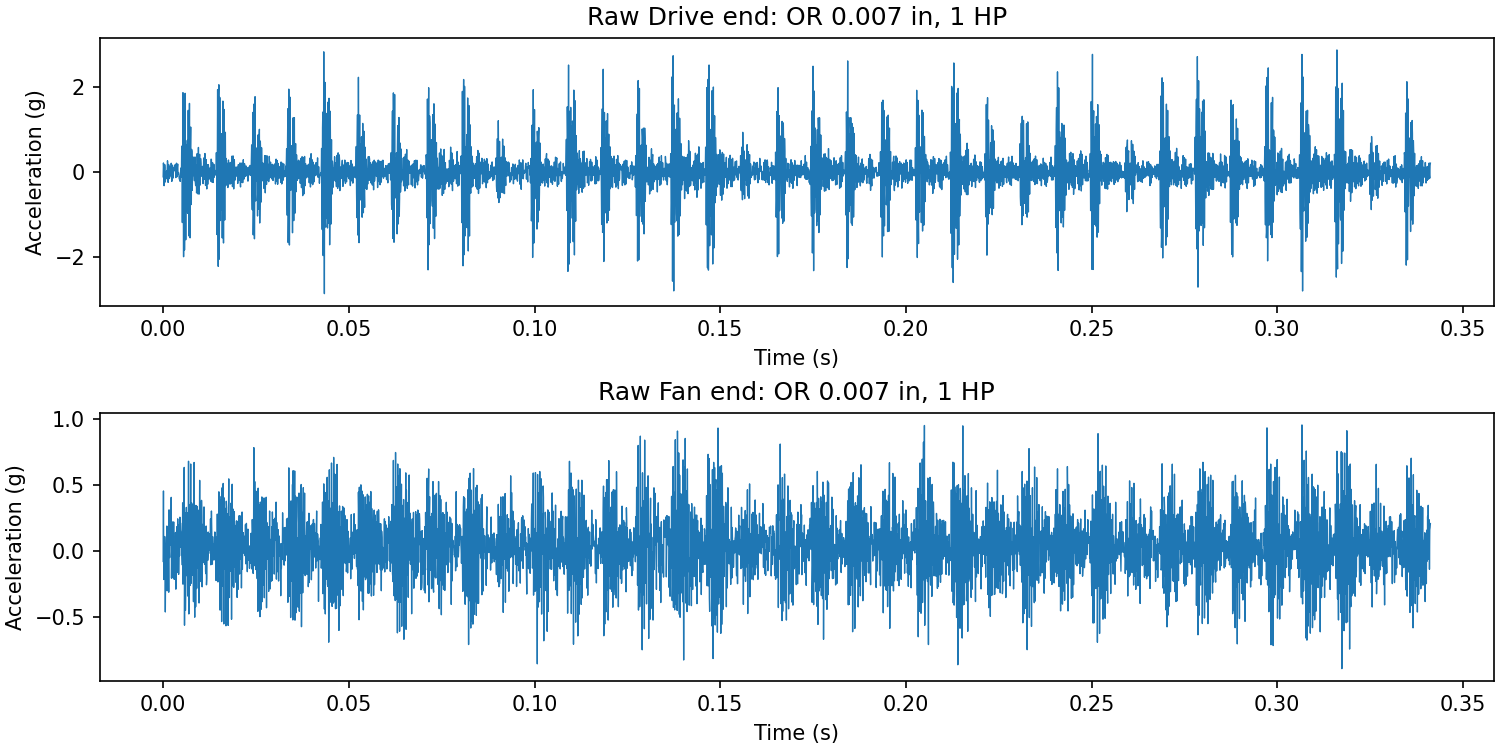

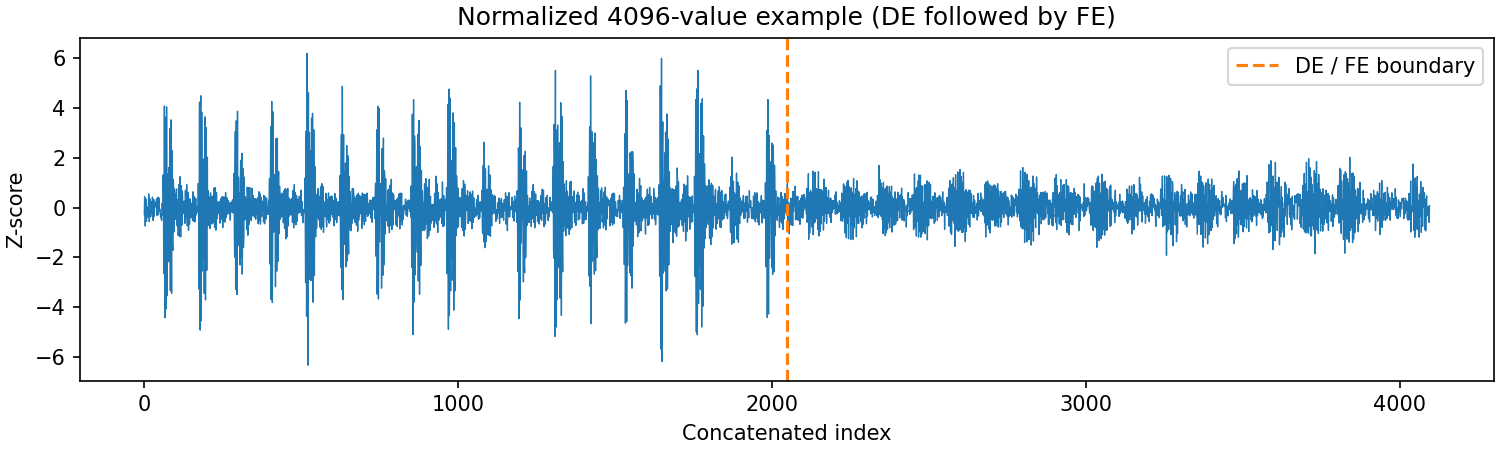

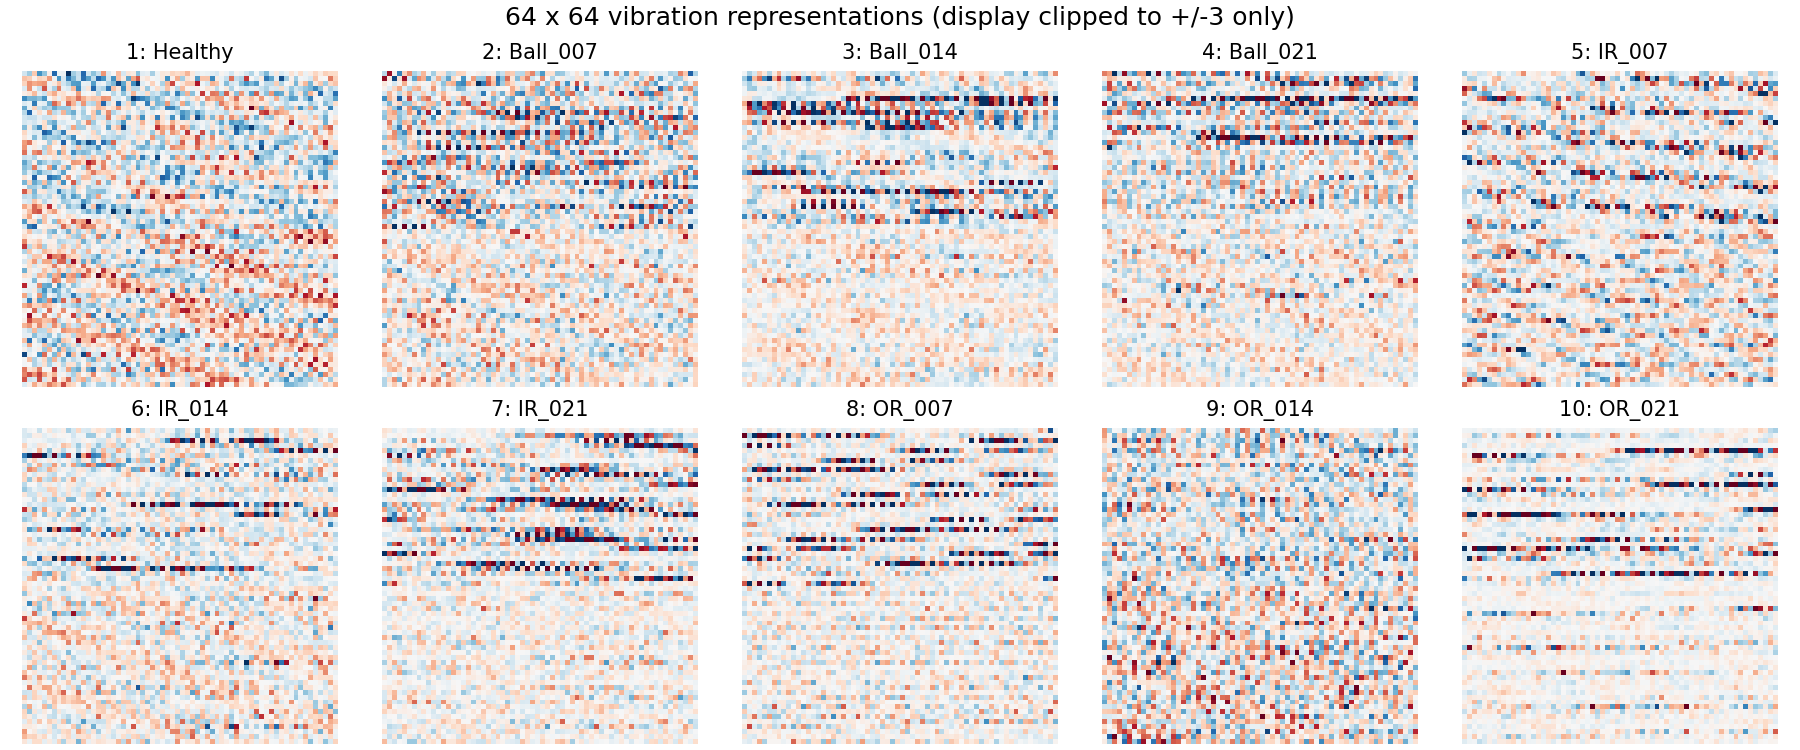

In [6]:
# Check the normalized 64 x 64 inputs and plot sample signals
# Each input contains 2048 drive-end and 2048 fan-end samples.
# Healthy recordings are assumed to be 48 kHz and resampled to 12 kHz.

for c, x in arrays.items():
    assert x.shape[1:] == (1, 64, 64) and torch.isfinite(x).all()
    assert torch.allclose(x.mean((1, 2, 3)), torch.zeros(len(x)), atol=1e-5)
save_preprocessing_figures(arrays, manifest, DATASET_PATH, RESULTS / "figures")
for figure in ["raw_signal.png", "processed_signal.png", "example_samples.png"]:
    display(Image(filename=str(RESULTS / "figures" / figure)))

In [7]:
# CNN: four convolution blocks followed by an N-class output layer
# Query samples use batch-normalization statistics from the support set.

class BearingCNN(nn.Module):
    def __init__(self, ways):
        super().__init__()
        self.blocks = nn.ModuleList([
            nn.ModuleDict({'conv': nn.Conv2d(1 if i == 0 else 64, 64, 3, padding=1),
                           'bn': nn.BatchNorm2d(64, track_running_stats=False),
                           'relu': nn.ReLU(), 'pool': nn.MaxPool2d(2)})
            for i in range(4)])
        self.head = nn.Linear(64 * 4 * 4, ways)

    def forward(self, x, bn_stats=None, return_stats=False):
        stats = []
        for i, block in enumerate(self.blocks):
            x = block['conv'](x)
            if bn_stats is None:
                mean = x.mean(dim=(0, 2, 3), keepdim=True)
                var = x.var(dim=(0, 2, 3), unbiased=False, keepdim=True)
            else:
                mean, var = bn_stats[i]
            stats.append((mean, var))
            bn = block['bn']
            x = (x - mean) * torch.rsqrt(var + bn.eps)
            x = x * bn.weight[None, :, None, None] + bn.bias[None, :, None, None]
            x = block['pool'](block['relu'](x))
        logits = self.head(x.flatten(1))
        # CrossEntropyLoss includes log-softmax, so return unnormalized logits.
        if return_stats:
            return logits, stats
        return logits


def parameter_counts(model):
    return {'total': sum(p.numel() for p in model.parameters()),
            'trainable': sum(p.numel() for p in model.parameters() if p.requires_grad)}

In [8]:
# Check model size and output shape for both tasks

for ways in [3, 5]:
    cnn = BearingCNN(ways)
    print(f"\n{ways}-way CNN:")
    print(cnn)
    print(parameter_counts(cnn))
    print("Logit shape:", tuple(cnn(torch.zeros(ways * 5, 1, 64, 64)).shape))
del cnn


3-way CNN:
BearingCNN(
  (blocks): ModuleList(
    (0): ModuleDict(
      (conv): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1-3): 3 x ModuleDict(
      (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (head): Linear(in_features=1024, out_features=3, bias=True)
)
{'total': 115011, 'trainable': 115011}


Logit shape: (15, 3)

5-way CNN:
BearingCNN(
  (blocks): ModuleList(
    (0): ModuleDict(
      (conv): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1-3): 3 x ModuleDict(
      (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (head): Linear(in_features=1024, out_features=5, bias=True)
)
{'total': 117061, 'trainable': 117061}


Logit shape: (25, 5)


In [9]:
# Sample N classes with K support examples per class
# Support and query examples must be separate.

@dataclass
class Episode:
    support_x: torch.Tensor
    support_y: torch.Tensor
    query_x: torch.Tensor
    query_y: torch.Tensor
    class_ids: list

    def to(self, device):
        return Episode(self.support_x.to(device), self.support_y.to(device),
                       self.query_x.to(device), self.query_y.to(device), self.class_ids)


class TaskSampler:
    def __init__(self, support_pool, ways, shots, queries, seed, query_pool=None):
        self.pool, self.query_pool = support_pool, query_pool
        self.ways, self.shots, self.queries = ways, shots, queries
        self.rng = np.random.default_rng(seed)
        assert 0 < ways <= len(support_pool)
        if query_pool is not None:
            assert set(query_pool) == set(support_pool)

    def sample(self):
        classes = self.rng.choice(sorted(self.pool), self.ways, replace=False).tolist()
        support_data, query_data, support_labels, query_labels = [], [], [], []
        for label, class_id in enumerate(classes):
            if self.query_pool is None:
                sample_indices = self.rng.choice(len(self.pool[class_id]), self.shots + self.queries, replace=False)
                support_indices, query_indices = sample_indices[:self.shots], sample_indices[self.shots:]
                assert set(support_indices).isdisjoint(query_indices)
                support_data.append(self.pool[class_id][support_indices])
                query_data.append(self.pool[class_id][query_indices])
            else:
                support_indices = self.rng.choice(len(self.pool[class_id]), self.shots, replace=False)
                query_indices = self.rng.choice(len(self.query_pool[class_id]), self.queries, replace=False)
                support_data.append(self.pool[class_id][support_indices])
                query_data.append(self.query_pool[class_id][query_indices])
            support_labels.append(torch.full((self.shots,), label, dtype=torch.long))
            query_labels.append(torch.full((self.queries,), label, dtype=torch.long))
        return Episode(torch.cat(support_data), torch.cat(support_labels), torch.cat(query_data), torch.cat(query_labels), classes)

In [10]:
# MAML: adapt on the support set, then calculate the query loss
# Inner update: adapted weights = weights - learning rate * support gradient
# create_graph=True lets the outer gradient pass through the inner update.

class MAML(nn.Module):
    def __init__(self, ways, inner_lr=.01, inner_steps=1, learn_inner_lr=True):
        super().__init__()
        self.net = BearingCNN(ways)
        self.inner_lr, self.inner_steps = inner_lr, inner_steps
        self.learn_inner_lr = learn_inner_lr
        self.rate_keys = {name: name.rsplit('.', 1)[0].replace('.', '_')
                          for name, _ in self.net.named_parameters()}
        # Each layer shares one learning rate for its weights and bias.
        self.rates = nn.ParameterDict({key: nn.Parameter(torch.full((inner_steps,), inner_lr))
                                       for key in sorted(set(self.rate_keys.values()))}
                                      if learn_inner_lr else {})

    def adapt(self, support_x, support_y, create_graph=True):
        adapted_weights = OrderedDict(self.net.named_parameters())
        for step in range(self.inner_steps):
            logits = functional_call(self.net, adapted_weights, (support_x,))
            loss = F.cross_entropy(logits, support_y)
            gradients = torch.autograd.grad(loss, tuple(adapted_weights.values()), create_graph=create_graph)
            # theta' = theta - alpha * grad(L_support).
            # Keep this update differentiable for the outer step.
            updated_weights = OrderedDict()
            for (name, weight), gradient in zip(adapted_weights.items(), gradients):
                updated_weights[name] = weight - self.rate(name, step) * gradient
            adapted_weights = updated_weights
        return adapted_weights

    def rate(self, name, step):
        if self.learn_inner_lr:
            return self.rates[self.rate_keys[name]][step]
        return self.inner_lr

    def predict(self, adapted_weights, support_x, query_x):
        # Recompute normalization on support at adapted weights, then freeze
        # those statistics across query examples. Query labels are never used.
        _, stats = functional_call(self.net, adapted_weights, (support_x,), {'return_stats': True})
        return functional_call(self.net, adapted_weights, (query_x,), {'bn_stats': stats})

    def task_loss(self, episode, create_graph=True):
        adapted_weights = self.adapt(episode.support_x, episode.support_y, create_graph=create_graph)
        logits = self.predict(adapted_weights, episode.support_x, episode.query_x)
        return F.cross_entropy(logits, episode.query_y), logits

In [11]:
# Inspect one 3-way 5-shot training task

cfg = Config(dataset_path=DATASET_PATH)
train_pool, support_pool, query_pool, split_manifest = make_pools(
    arrays, manifest, 3, 5, cfg.queries, cfg.train_queries, cfg.train_samples_per_class, seed=1)
episode = TaskSampler(train_pool, ways=3, shots=5, queries=4, seed=1).sample()
print("Support:", episode.support_x.shape, "labels:", episode.support_y.tolist())
print("Query:", episode.query_x.shape, "labels:", episode.query_y.tolist())
print("Meta-train classes:", sorted(train_pool), "| unseen classes:", sorted(support_pool))
assert set(train_pool).isdisjoint(support_pool)

Support: torch.Size([15, 1, 64, 64]) labels: [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2]
Query: torch.Size([12, 1, 64, 64]) labels: [0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2]
Meta-train classes: [1, 2, 3, 4, 5, 6, 7] | unseen classes: [8, 9, 10]


In [12]:
# Evaluate each task using a fresh copy of the trained initialization
# Only support labels are used for adaptation.

def evaluate_model(model, sampler, tasks, device='cpu'):
    model.eval()
    predictions, episode_scores = [], []
    before = {k: v.detach().clone() for k, v in model.state_dict().items()}
    for task in range(tasks):
        episode = sampler.sample().to(device)
        # Adaptation requires gradients even at test time. Outer learning is off.
        with torch.enable_grad():
            fast = model.adapt(episode.support_x, episode.support_y, create_graph=False)
        with torch.no_grad():
            logits = model.predict(fast, episode.support_x, episode.query_x)
            local_pred = logits.argmax(1).cpu().numpy()
        local_true = episode.query_y.cpu().numpy()
        classes = np.asarray(episode.class_ids)
        episode_scores.append(float(np.mean(local_pred == local_true)))
        for truth, pred in zip(classes[local_true], classes[local_pred]):
            # Map episode-local labels back to physical classes before aggregating.
            predictions.append({'task': task, 'true_class': int(truth), 'predicted_class': int(pred)})
    assert all(torch.equal(before[k], v) for k, v in model.state_dict().items()), 'Test mutated initialization'
    frame = pd.DataFrame(predictions)
    labels = sorted(sampler.pool)
    p, r, f1, _ = precision_recall_fscore_support(frame.true_class, frame.predicted_class,
                                                labels=labels, average='macro', zero_division=0)
    metrics = {'accuracy': accuracy_score(frame.true_class, frame.predicted_class),
               'precision_macro': float(p), 'recall_macro': float(r), 'f1_macro': float(f1),
               'episode_accuracy_std': float(np.std(episode_scores, ddof=1)) if tasks > 1 else 0.,
               'eval_tasks': tasks, 'query_predictions': len(frame),
               'episode_accuracies': episode_scores, 'class_ids': labels,
               'confusion_matrix': confusion_matrix(frame.true_class, frame.predicted_class, labels=labels).tolist()}
    return metrics, frame


def plot_confusion(matrix, labels, path, title):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    import seaborn as sns
    fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
    names = [CLASSES[c][0] for c in labels]
    sns.heatmap(np.asarray(matrix), annot=True, fmt='d', cmap='Blues',
                xticklabels=names, yticklabels=names, ax=ax)
    ax.set(title=title, xlabel='Predicted class', ylabel='True class')
    fig.savefig(path, dpi=150)
    plt.close(fig)


def evaluate_checkpoint(checkpoint_path, dataset_path=None, tasks=None):
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    config = Config(**checkpoint['config'])
    if dataset_path:
        config.dataset_path = str(dataset_path)
    if tasks is not None:
        config.eval_tasks = tasks
    torch.set_num_threads(config.threads)
    arrays, manifest, _ = load_dataset(config.dataset_path)
    _, support, query, _ = make_pools(arrays, manifest, config.ways, config.shots,
                                     config.queries, config.train_queries,
                                     config.train_samples_per_class, config.seed)
    model = MAML(config.ways, config.inner_lr, config.inner_steps, config.learn_inner_lr)
    model.load_state_dict(checkpoint['model'])
    sampler = TaskSampler(support, config.ways, config.shots, config.queries,
                          config.seed + 20000, query_pool=query)
    return evaluate_model(model, sampler, config.eval_tasks)

In [13]:
# Debug checks and meta-training
# Adam updates the shared weights using the query loss.
# Use the final training checkpoint; do not select it using test accuracy.

def seed_everything(seed, threads=4):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)


def directories(root):
    root = Path(root)
    for sub in ['figures', 'tables', 'metrics', 'checkpoints']:
        (root / sub).mkdir(parents=True, exist_ok=True)
    return root


def run_debug(config, dataset=None):
    """Real-data smoke test + repeated-task loss decrease + meta-gradient checks."""
    seed_everything(config.seed, config.threads)
    arrays, manifest, sources = dataset or load_dataset(config.dataset_path)
    train, support, query, selected = make_pools(arrays, manifest, config.ways, config.shots,
                                               config.queries, config.train_queries,
                                               config.train_samples_per_class, config.seed)
    sampler = TaskSampler(train, config.ways, config.shots, config.train_queries, config.seed)
    episode = sampler.sample().to(config.device)
    assert episode.support_x.shape == (config.ways * config.shots, 1, 64, 64)
    assert torch.bincount(episode.support_y).tolist() == [config.shots] * config.ways
    assert torch.bincount(episode.query_y).tolist() == [config.train_queries] * config.ways
    assert torch.isfinite(episode.support_x).all()
    model = MAML(config.ways, config.inner_lr, config.inner_steps, config.learn_inner_lr).to(config.device)
    snapshot = {n: p.detach().clone() for n, p in model.named_parameters()}
    model.adapt(episode.support_x, episode.support_y)
    assert all(torch.equal(snapshot[n], p) for n, p in model.named_parameters()), 'Adapt changed base weights'
    full_loss, _ = model.task_loss(episode, create_graph=True)
    full = torch.autograd.grad(full_loss, tuple(model.net.parameters()))
    first_loss, _ = model.task_loss(episode, create_graph=False)
    first = torch.autograd.grad(first_loss, tuple(model.net.parameters()))
    second_order_difference = float(sum((a-b).square().sum() for a, b in zip(full, first)).sqrt())
    assert second_order_difference > 1e-8, 'Second-order path is missing'
    optimizer = torch.optim.Adam(model.parameters(), lr=config.outer_lr)
    losses, grad_norms = [], []
    start = time.perf_counter()
    for i in range(12):
        optimizer.zero_grad(set_to_none=True)
        loss, logits = model.task_loss(episode)
        assert torch.isfinite(loss)
        loss.backward()
        for name, p in model.named_parameters():
            assert p.grad is not None and torch.isfinite(p.grad).all(), f'Invalid gradient: {name}'
        grad_norms.append(float(torch.nn.utils.clip_grad_norm_(model.parameters(), 10.)))
        losses.append(float(loss.detach()))
        optimizer.step()
        print(f'DEBUG {config.ways}-way step {i+1}/12 loss={losses[-1]:.4f}', flush=True)
    assert np.mean(losses[-3:]) < np.mean(losses[:3]), 'Repeated-task loss did not decrease'
    test_sampler = TaskSampler(support, config.ways, config.shots, config.queries,
                               config.seed + 20000, query_pool=query)
    metrics, _ = evaluate_model(model, test_sampler, tasks=2, device=config.device)
    output = directories(config.results_path)
    summary = {'passed': True, 'ways': config.ways, 'losses': losses,
               'gradient_norms': grad_norms, 'full_vs_first_order_gradient_l2': second_order_difference,
               'seconds': time.perf_counter() - start,
               'checks': ['balanced task labels', 'disjoint classes/files/support-query windows',
                          'finite gradients including learned rates', 'second-order gradient path',
                          'base parameters unchanged by adaptation/evaluation', 'repeated-task loss decreases'],
               'warning': 'Debug overfits one training episode; NOT a reported experiment result.'}
    (output / 'metrics' / f'debug_{config.ways}way.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2), flush=True)
    return summary


def run_experiment(config, dataset=None, reuse=False):
    config.validate()
    if config.fast_debug:
        return run_debug(config, dataset)
    output = directories(config.results_path)
    metrics_file = output / 'metrics' / f'{config.run_name}.json'
    if reuse and metrics_file.exists():
        saved = json.loads(metrics_file.read_text())
        if saved['config'] == config.to_dict():
            current_sources = (dataset or load_dataset(config.dataset_path))[2]
            hashes = dict(zip(current_sources.filename, current_sources.sha256))
            if saved['data_sha256'] != hashes:
                raise ValueError('Raw recordings changed since the saved run; retrain instead of reusing.')
            for artifact in [output / 'checkpoints' / f'{config.run_name}.pt',
                             output / 'metrics' / f'{config.run_name}_history.csv',
                             output / 'metrics' / f'{config.run_name}_predictions.csv']:
                if not artifact.exists():
                    raise FileNotFoundError(f'Incomplete saved run: {artifact}; retrain with reuse=False.')
            print(f'Reusing completed run {config.run_name}', flush=True)
            return saved
        raise ValueError(f'Existing {metrics_file} has a different config. Use reuse=False.')
    seed_everything(config.seed, config.threads)
    arrays, manifest, sources = dataset or load_dataset(config.dataset_path)
    train, support, query, selected = make_pools(arrays, manifest, config.ways, config.shots,
                                               config.queries, config.train_queries,
                                               config.train_samples_per_class, config.seed)
    selected.to_csv(output / 'tables' / f'{config.run_name}_split.csv', index=False)
    sources.to_csv(output / 'tables' / 'source_manifest.csv', index=False)
    manifest.to_csv(output / 'tables' / 'window_manifest.csv', index=False)
    model = MAML(config.ways, config.inner_lr, config.inner_steps, config.learn_inner_lr).to(config.device)
    print(model.net, flush=True)
    print(f'CNN parameters: {parameter_counts(model.net)}; MAML total: {parameter_counts(model)}', flush=True)
    sampler = TaskSampler(train, config.ways, config.shots, config.train_queries, config.seed + 10000)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.outer_lr)
    history = []
    start = time.perf_counter()
    for iteration in range(1, config.iterations + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        losses, accuracies = [], []
        # Backpropagate tasks sequentially: same mean meta-gradient, less memory.
        for _ in range(config.meta_batch_size):
            episode = sampler.sample().to(config.device)
            loss, logits = model.task_loss(episode, create_graph=True)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite query loss')
            (loss / config.meta_batch_size).backward()
            losses.append(float(loss.detach()))
            accuracies.append(float((logits.argmax(1) == episode.query_y).float().mean()))
        gradient_norm = float(torch.nn.utils.clip_grad_norm_(model.parameters(), 10., error_if_nonfinite=True))
        # theta <- theta - beta * meta-gradient (Adam outer update).
        optimizer.step()
        history.append({'iteration': iteration, 'query_loss': np.mean(losses),
                        'query_accuracy': np.mean(accuracies), 'gradient_norm': gradient_norm})
        if iteration == 1 or iteration % 10 == 0 or iteration == config.iterations:
            print(f'{config.run_name} {iteration}/{config.iterations} '
                  f'loss={np.mean(losses):.4f} acc={np.mean(accuracies):.3f} '
                  f'elapsed={time.perf_counter()-start:.1f}s', flush=True)
    train_seconds = time.perf_counter() - start
    pd.DataFrame(history).to_csv(output / 'metrics' / f'{config.run_name}_history.csv', index=False)
    checkpoint_path = output / 'checkpoints' / f'{config.run_name}.pt'
    torch.save({'model': model.state_dict(), 'config': config.to_dict()}, checkpoint_path)
    test_sampler = TaskSampler(support, config.ways, config.shots, config.queries,
                               config.seed + 20000, query_pool=query)
    evaluation_start = time.perf_counter()
    metrics, predictions = evaluate_model(model, test_sampler, config.eval_tasks, config.device)
    metrics.update({'config': config.to_dict(), 'train_seconds': train_seconds,
                    'evaluation_seconds': time.perf_counter() - evaluation_start,
                    'cnn_parameters': parameter_counts(model.net), 'maml_parameters': parameter_counts(model),
                    'environment': {'python': platform.python_version(), 'torch': torch.__version__,
                                    'platform': platform.platform(), 'device': config.device},
                    'learned_rates': {k: v.detach().cpu().tolist() for k, v in model.rates.items()},
                    'data_sha256': dict(zip(sources.filename, sources.sha256)),
                    'train_class_ids': sorted(train), 'test_class_ids': sorted(support),
                    'model_selection': 'Final iteration, fixed budget; no test-based selection'})
    predictions.to_csv(output / 'metrics' / f'{config.run_name}_predictions.csv', index=False)
    metrics_file.write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    plot_confusion(metrics['confusion_matrix'], metrics['class_ids'],
                   output / 'figures' / f'{config.run_name}_confusion_matrix.png', config.run_name)
    print(f'COMPLETE {config.run_name}: {metrics["accuracy"]*100:.2f}% test accuracy', flush=True)
    return metrics

In [14]:
# Run the debug checks before the experiments
# Debug accuracy is not included in the reported results.

FAST_DEBUG = True
debug_results = []
for ways in [3, 5]:
    debug_cfg = Config(ways=ways, dataset_path=DATASET_PATH, results_path=str(RESULTS), fast_debug=FAST_DEBUG)
    debug_results.append(run_debug(debug_cfg, dataset))
assert all(result["passed"] for result in debug_results)
FAST_DEBUG = False
print("Debug passed; actual experiment mode:", not FAST_DEBUG)

DEBUG 3-way step 1/12 loss=1.8121


DEBUG 3-way step 2/12 loss=1.8930


DEBUG 3-way step 3/12 loss=0.5057


DEBUG 3-way step 4/12 loss=0.2236


DEBUG 3-way step 5/12 loss=0.0939


...

DEBUG 5-way step 10/12 loss=0.0069


DEBUG 5-way step 11/12 loss=0.0057


DEBUG 5-way step 12/12 loss=0.0045


{
  "passed": true,
  "ways": 5,
  "losses": [
    1.5387241840362549,
    0.7185394763946533,
    0.35033220052719116,
    0.20441587269306183,
    0.07483087480068207,
    0.0330023467540741,
    0.016808204352855682,
    0.011000832542777061,
    0.008304843679070473,
    0.006906844675540924,
    0.00568034453317523,
    0.004517768044024706
  ],
  "gradient_norms": [
    44.6369514465332,
    62.89141082763672,
    49.143314361572266,
    17.530614852905273,
    3.9680471420288086,
    1.4256956577301025,
    0.4054567217826843,
    0.8797035813331604,
    1.0214970111846924,
    1.0252947807312012,
    0.9066324830055237,
    0.7208986282348633
  ],
  "full_vs_first_order_gradient_l2": 15.1653470993042,
  "seconds": 18.305516800000078,
  "checks": [
    "balanced task labels",
    "disjoint classes/files/support-query windows",
    "finite gradients including learned rates",
    "second-order gradient path",
    "base parameters unchanged by adaptation/evaluation",
    "repeated-

Debug passed; actual experiment mode: True


In [15]:
# Summarize saved runs and generate tables and plots

PAPER = {(3, 5, True): (90.36, 1.38), (5, 5, True): (79.98, 1.17),
         (3, 1, True): (88.39, 2.95), (3, 5, False): (85.53, 1.07),
         (5, 5, False): (59.86, 1.04), (3, 1, False): (82.73, 3.12)}


def markdown_table(frame):
    # Avoid a hidden tabulate dependency.
    lines = ['| ' + ' | '.join(map(str, frame.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(lines)


def summarize_results(results_path=ROOT / 'results'):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    root = Path(results_path)
    records, complete = [], []
    for path in sorted((root / 'metrics').glob('*way_*shot_*_seed*.json')):
        metric = json.loads(path.read_text())
        config = metric['config']
        if config['fast_debug']:
            continue
        complete.append(metric)
        records.append({'experiment': f'{config["ways"]}-way {config["shots"]}-shot',
                        'ways': config['ways'], 'shots': config['shots'],
                        'learn_inner_lr': config['learn_inner_lr'], 'seed': config['seed'],
                        'accuracy_percent': 100 * metric['accuracy'],
                        'precision_macro_percent': 100 * metric['precision_macro'],
                        'recall_macro_percent': 100 * metric['recall_macro'],
                        'f1_macro_percent': 100 * metric['f1_macro'],
                        'train_seconds': metric['train_seconds'],
                        'iterations': config['iterations'], 'meta_batch_size': config['meta_batch_size'],
                        'eval_tasks': config['eval_tasks'], 'run_name': path.stem})
    if not records:
        raise FileNotFoundError('No completed real experiments to summarize')
    per_seed = pd.DataFrame(records)
    per_seed.to_csv(root / 'tables' / 'per_seed_results.csv', index=False)
    comparison, aggregate = [], []
    for (ways, shots, learned), group in per_seed.groupby(['ways', 'shots', 'learn_inner_lr']):
        matching = [m for m in complete if (m['config']['ways'], m['config']['shots'],
                                             m['config']['learn_inner_lr']) == (ways, shots, learned)]
        # Different seeds must share all scientific settings before aggregation.
        signatures = [{k: v for k, v in m['config'].items()
                       if k not in ['seed', 'dataset_path', 'results_path']} for m in matching]
        assert all(s == signatures[0] for s in signatures), 'Cannot pool different experimental settings'
        assert all(m['data_sha256'] == matching[0]['data_sha256'] for m in matching)
        mean = group.accuracy_percent.mean()
        std = group.accuracy_percent.std(ddof=1) if len(group) > 1 else float('nan')
        label = f'{ways}-way {shots}-shot ({"learnable" if learned else "fixed"} lr)'
        ours = f'{mean:.2f} +/- {std:.2f}%' if len(group) > 1 else f'{mean:.2f}% (1 seed; SD unavailable)'
        paper = PAPER.get((ways, shots, learned))
        comparison.append({'Experiment': label,
                           'Paper Result': f'{paper[0]:.2f} +/- {paper[1]:.2f}%' if paper else 'Not tabulated',
                           'Our Result': ours,
                           'Difference': f'{mean-paper[0]:+.2f} percentage points' if paper else 'N/A'})
        row = {'experiment': label, 'seeds': len(group), 'accuracy_mean_percent': mean,
               'accuracy_std_percent': std}
        for column in ['precision_macro_percent', 'recall_macro_percent', 'f1_macro_percent']:
            row[column.replace('_percent', '_mean_percent')] = group[column].mean()
            row[column.replace('_percent', '_std_percent')] = group[column].std(ddof=1)
        aggregate.append(row)
        matrix = np.sum([m['confusion_matrix'] for m in matching], axis=0)
        suffix = '' if learned else '_fixed'
        plot_confusion(matrix, matching[0]['class_ids'],
                       root / 'figures' / f'confusion_matrix_{ways}way_{shots}shot{suffix}.png',
                       f'{label}: pooled {len(group)} seeds, physical class labels')
        pd.DataFrame(matrix, index=matching[0]['class_ids'], columns=matching[0]['class_ids']).to_csv(
            root / 'tables' / f'confusion_matrix_{ways}way_{shots}shot{suffix}.csv')
    comparison_frame = pd.DataFrame(comparison)
    comparison_frame.to_csv(root / 'tables' / 'paper_vs_ours.csv', index=False)
    note = ('\n\nPaper: Table V, arXiv:2007.12851v4. Difference = ours minus paper (percentage points). '
            'Our standard deviation is across independent training seeds (sample SD, ddof=1). '
            'These are contextual comparisons, not matched-protocol replications: reduced training budget, '
            'non-overlapping windows, explicit normalization and support-only batch normalization differ.\n')
    (root / 'tables' / 'paper_vs_ours.md').write_text(markdown_table(comparison_frame) + note, encoding='utf-8')
    pd.DataFrame(aggregate).to_csv(root / 'tables' / 'aggregate_results.csv', index=False)
    for metric, filename, ylabel in [('query_loss', 'training_loss.png', 'Meta-training query cross-entropy'),
                                      ('query_accuracy', 'training_accuracy.png', 'Meta-training query accuracy')]:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
        for ax, ways in zip(axes, [3, 5]):
            for record in records:
                if record['ways'] != ways:
                    continue
                history = pd.read_csv(root / 'metrics' / f'{record["run_name"]}_history.csv')
                label = f'{record["shots"]}-shot seed {record["seed"]}'
                ax.plot(history.iteration, history[metric], alpha=.12)
                ax.plot(history.iteration, history[metric].rolling(10, min_periods=1).mean(), label=label)
            ax.set(title=f'{ways}-way (10-iteration moving average)', xlabel='Meta-iteration', ylabel=ylabel)
            if metric == 'query_accuracy':
                ax.set_ylim(0, 1.03)
            if ax.lines:
                ax.legend(fontsize=8)
            ax.grid(alpha=.2)
        fig.savefig(root / 'figures' / filename, dpi=150)
        plt.close(fig)
    return per_seed, pd.DataFrame(aggregate), comparison_frame

Reusing completed run 3way_5shot_learned_seed1


Reusing completed run 3way_5shot_learned_seed2


Reusing completed run 3way_5shot_learned_seed3


,seed,accuracy_percent,precision_macro,recall_macro,f1_macro
0,1,95.333333,0.958700,0.953333,0.953118
1,2,93.851852,0.947163,0.938519,0.938041
2,3,92.962963,0.931831,0.929630,0.929483


Accuracy mean +/- sample SD (%): 94.0493827160494 +/- 1.1974672249858942


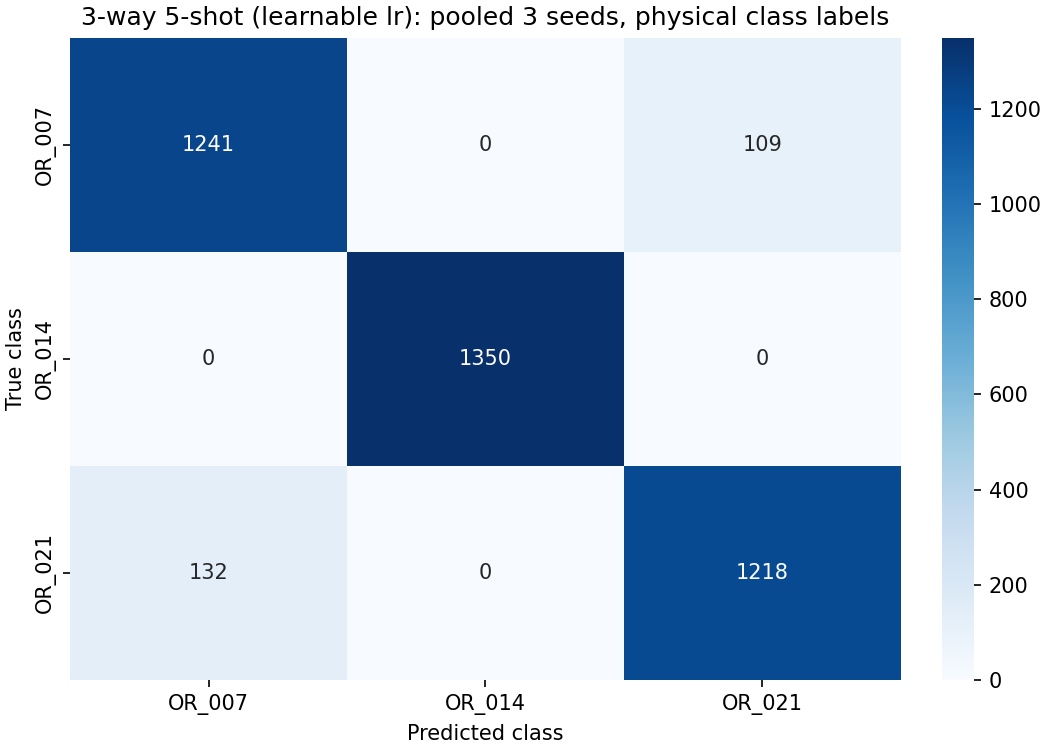

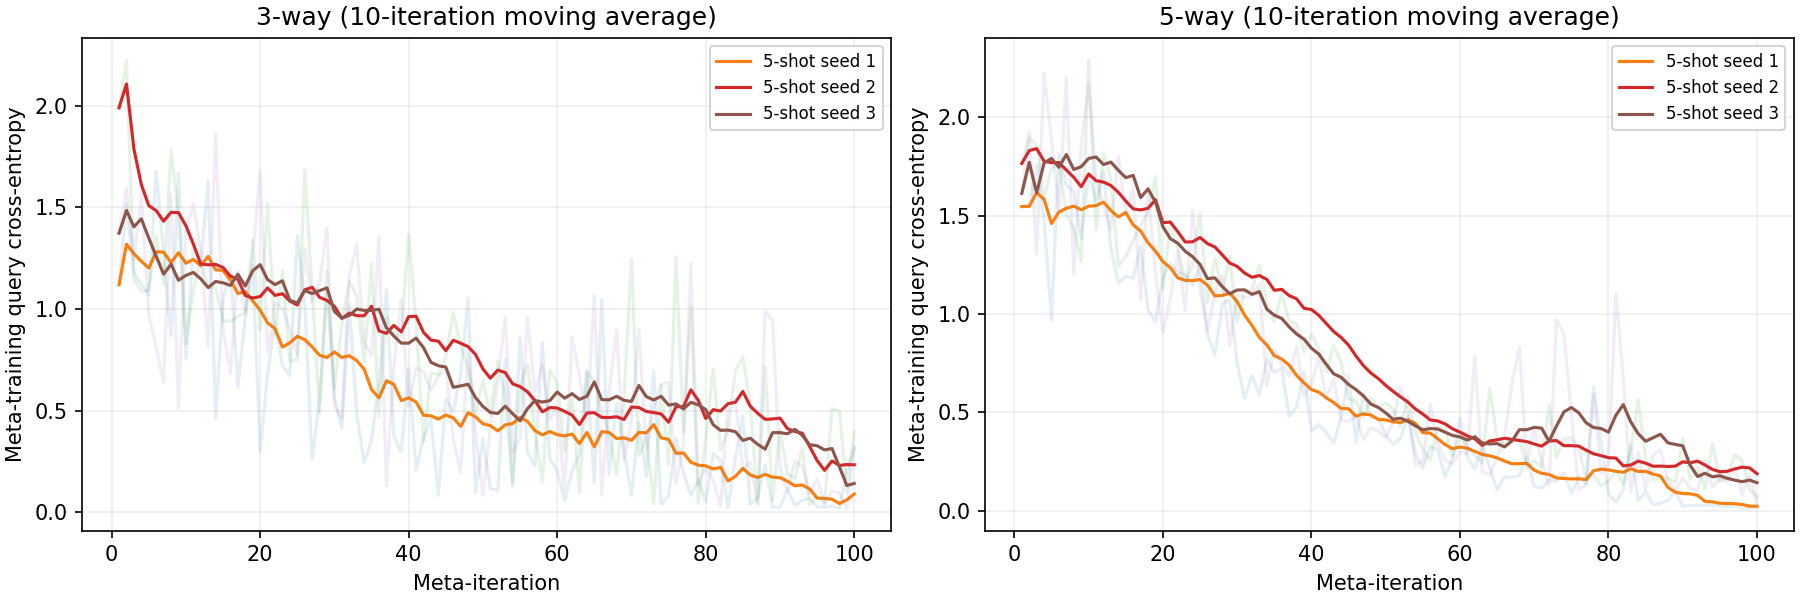

In [16]:
# 3-way 5-shot: train on classes 1-7, test on classes 8-10
# Three seeds, 30 test tasks per seed, 15 query samples per class.

runs_3way = []
for seed in SEEDS:
    config = Config(ways=3, shots=5, seed=seed, dataset_path=DATASET_PATH,
                    results_path=str(RESULTS), fast_debug=FAST_DEBUG)
    runs_3way.append(run_experiment(config, dataset, reuse=not RERUN_TRAINING))
display(pd.DataFrame([{ "seed": r["config"]["seed"], "accuracy_percent": 100*r["accuracy"],
                       "precision_macro": r["precision_macro"], "recall_macro": r["recall_macro"],
                       "f1_macro": r["f1_macro"]} for r in runs_3way]))
print("Accuracy mean +/- sample SD (%):", np.mean([r["accuracy"] for r in runs_3way])*100,
      "+/-", np.std([r["accuracy"] for r in runs_3way], ddof=1)*100)
summarize_results(RESULTS)
display(Image(filename=str(RESULTS / "figures" / "confusion_matrix_3way_5shot.png")))
display(Image(filename=str(RESULTS / "figures" / "training_loss.png")))

Reusing completed run 5way_5shot_learned_seed1


Reusing completed run 5way_5shot_learned_seed2


Reusing completed run 5way_5shot_learned_seed3


,experiment,ways,shots,learn_inner_lr,seed,accuracy_percent,precision_macro_percent,recall_macro_percent,f1_macro_percent,train_seconds,iterations,meta_batch_size,eval_tasks
3,5-way 5-shot,5,5,True,1,58.666667,61.860295,58.666667,59.161614,144.186947,100,1,30
4,5-way 5-shot,5,5,True,2,52.444444,62.610085,52.444444,48.372998,155.690467,100,1,30
5,5-way 5-shot,5,5,True,3,62.977778,68.546132,62.977778,59.264220,165.847096,100,1,30


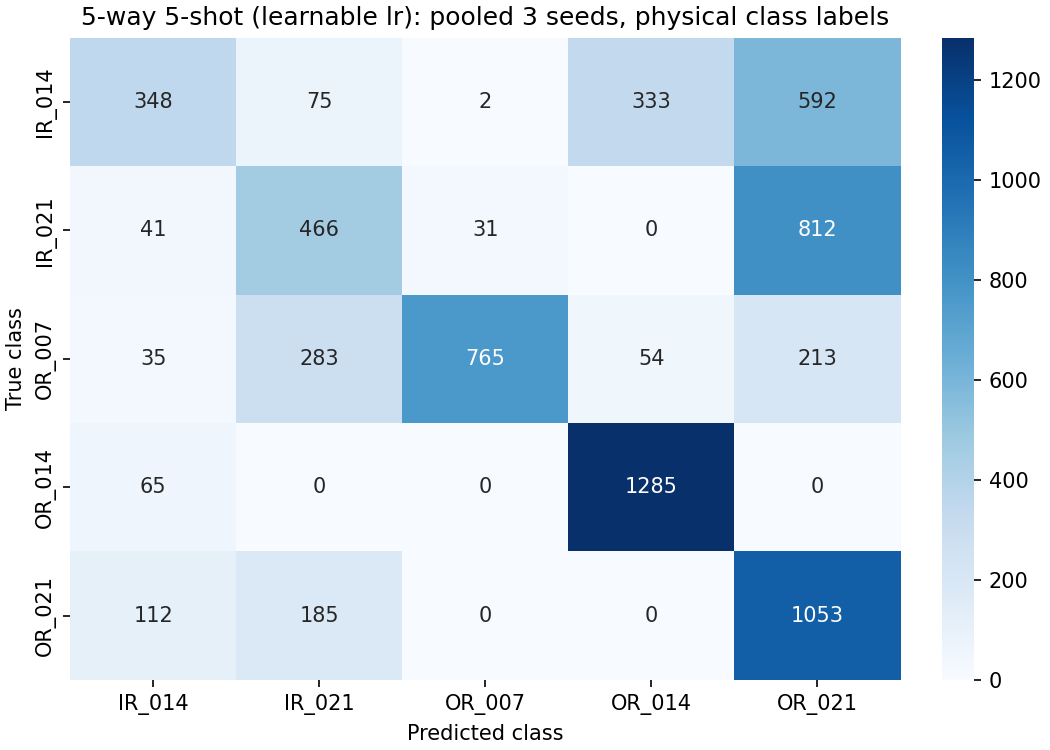

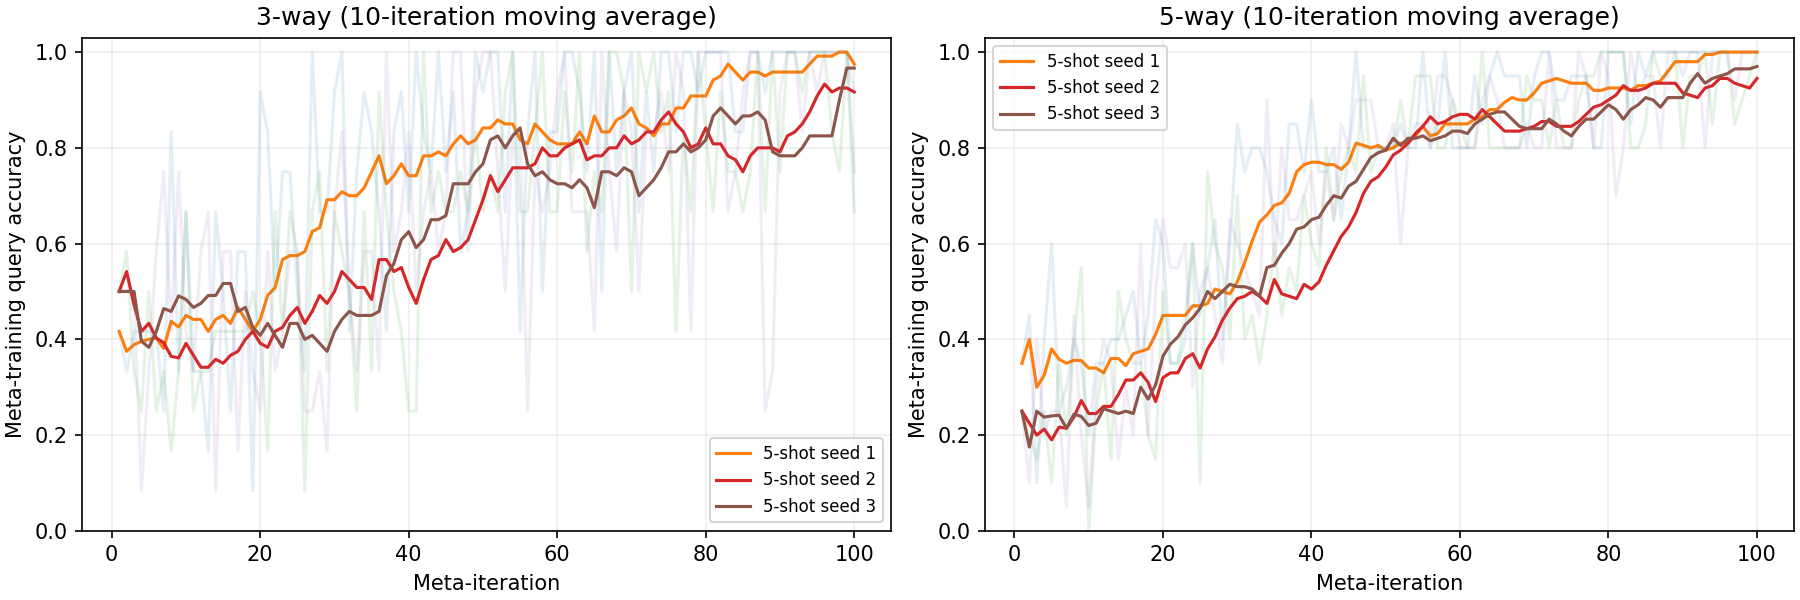

In [17]:
# 5-way 5-shot: train on classes 1-5, test on classes 6-10
# Use the same seeds and evaluation settings as the 3-way experiment.

runs_5way = []
for seed in SEEDS:
    config = Config(ways=5, shots=5, seed=seed, dataset_path=DATASET_PATH,
                    results_path=str(RESULTS), fast_debug=FAST_DEBUG)
    runs_5way.append(run_experiment(config, dataset, reuse=not RERUN_TRAINING))
per_seed, aggregate, comparison = summarize_results(RESULTS)
display(per_seed[per_seed.ways == 5].drop(columns=["run_name"]))
display(Image(filename=str(RESULTS / "figures" / "confusion_matrix_5way_5shot.png")))
display(Image(filename=str(RESULTS / "figures" / "training_accuracy.png")))

In [18]:
# Compare with the paper's learnable-rate results from Table V
# Different training budgets and preprocessing mean this is not an exact comparison.

display(aggregate)
display(comparison)
assert set(per_seed["seed"]) == set(SEEDS)
print("All measurements above come from saved completed experiments.")

,experiment,seeds,accuracy_mean_percent,accuracy_std_percent,precision_macro_mean_percent,precision_macro_std_percent,recall_macro_mean_percent,recall_macro_std_percent,f1_macro_mean_percent,f1_macro_std_percent
0,3-way 5-shot (learnable lr),3,94.049383,1.197467,94.589790,1.347898,94.049383,1.197467,94.021413,1.196624
1,5-way 5-shot (learnable lr),3,58.029630,5.295483,64.338837,3.662860,58.029630,5.295483,55.599611,6.258641


,Experiment,Paper Result,Our Result,Difference
0,3-way 5-shot (learnable lr),90.36 +/- 1.38%,94.05 +/- 1.20%,+3.69 percentage points
1,5-way 5-shot (learnable lr),79.98 +/- 1.17%,58.03 +/- 5.30%,-21.95 percentage points


All measurements above come from saved completed experiments.


In [19]:
# Accuracy across seeds and recall for each fault class
# Repeated windows are correlated; they are not independent bearing trials.

for _, row in aggregate.iterrows():
    display(Markdown(f"**{row['experiment']}:** {row['accuracy_mean_percent']:.2f}% mean accuracy, "
                     f"{row['accuracy_std_percent']:.2f} percentage-point sample SD across {int(row['seeds'])} seeds."))
for ways in [3, 5]:
    cm = pd.read_csv(RESULTS / "tables" / f"confusion_matrix_{ways}way_5shot.csv", index_col=0)
    recall = np.diag(cm.to_numpy()) / cm.sum(axis=1).to_numpy()
    display(pd.DataFrame({"class_id": cm.index, "pooled_class_recall": recall}))
print("Training curves report adapted meta-training query performance, not held-out test performance.")

**3-way 5-shot (learnable lr):** 94.05% mean accuracy, 1.20 percentage-point sample SD across 3 seeds.

**5-way 5-shot (learnable lr):** 58.03% mean accuracy, 5.30 percentage-point sample SD across 3 seeds.

,class_id,pooled_class_recall
0,8,0.919259
1,9,1.000000
2,10,0.902222


,class_id,pooled_class_recall
0,6,0.257778
1,7,0.345185
2,8,0.566667
3,9,0.951852
4,10,0.780000


Training curves report adapted meta-training query performance, not held-out test performance.


In [20]:
# Check data separation, gradients, checkpoints and saved metrics

def verify():
    seed_everything(91, 2)
    cfg = Config()
    arrays, windows, sources = load_dataset(cfg.dataset_path)
    assert len(sources) == 30 and len(arrays) == 10
    assert sources[sources.file_id == 99].iloc[0].de_key == 'X099_DE_time'
    assert sources.sha256.nunique() == 30
    checks = ['30 distinct real source recordings', '99.mat uses X099 channels']
    for file_id, rows in windows.groupby('file_id'):
        ordered = rows.sort_values('start')
        assert (ordered.stop.to_numpy()[:-1] <= ordered.start.to_numpy()[1:]).all()
        support = rows[rows.test_role == 'support']
        query = rows[rows.test_role == 'query']
        assert support.stop.max() + 2048 <= query.start.min()
    checks += ['all raw windows non-overlapping', 'purged temporal gap between test support/query pools']
    for ways in [3, 5]:
        train, support, query, selected = make_pools(arrays, windows, ways, 5, 15, 4, 9, 91)
        assert set(train).isdisjoint(support)
        train_files = set(selected[selected.experiment_role == 'meta_train'].file_id)
        test_files = set(selected[selected.experiment_role != 'meta_train'].file_id)
        assert train_files.isdisjoint(test_files)
        sampler1 = TaskSampler(train, ways, 5, 4, 23)
        sampler2 = TaskSampler(train, ways, 5, 4, 23)
        e = sampler1.sample()
        e2 = sampler2.sample()
        assert torch.equal(e.support_x, e2.support_x) and e.class_ids == e2.class_ids
        # Fixed-rate MAML must also carry finite meta-gradients.
        model = MAML(ways, learn_inner_lr=False)
        assert len(model.rates) == 0
        loss, _ = model.task_loss(e)
        loss.backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
        model.zero_grad(set_to_none=True)
        fast = model.adapt(e.support_x, e.support_y, create_graph=False)
        with torch.no_grad():
            full = model.predict(fast, e.support_x, e.query_x)
            individual = model.predict(fast, e.support_x, e.query_x[:1])
        assert torch.allclose(full[:1], individual, atol=2e-5, rtol=2e-5), 'Query batch dependence'
        checks += [f'{ways}-way reproducible task sampler and disjoint files/classes',
                   f'{ways}-way fixed-rate MAML finite gradients', f'{ways}-way query-batch independence']
    completed = []
    for ways in [3, 5]:
        for seed in [1, 2, 3]:
            name = f'{ways}way_5shot_learned_seed{seed}'
            base = ROOT / 'results' / 'metrics'
            metric = json.loads((base / f'{name}.json').read_text())
            pred = pd.read_csv(base / f'{name}_predictions.csv')
            accuracy = accuracy_score(pred.true_class, pred.predicted_class)
            precision, recall, f1, _ = precision_recall_fscore_support(
                pred.true_class, pred.predicted_class, labels=metric['class_ids'], average='macro', zero_division=0)
            for key, value in [('accuracy', accuracy), ('precision_macro', precision), ('recall_macro', recall), ('f1_macro', f1)]:
                assert np.isclose(metric[key], value, atol=1e-12)
            matrix = confusion_matrix(pred.true_class, pred.predicted_class, labels=metric['class_ids'])
            assert np.array_equal(matrix, metric['confusion_matrix'])
            assert len(pred) == metric['config']['eval_tasks'] * ways * metric['config']['queries']
            history = pd.read_csv(base / f'{name}_history.csv')
            assert len(history) == metric['config']['iterations']
            assert np.isfinite(history.select_dtypes('number')).all().all()
            checkpoint = ROOT / 'results' / 'checkpoints' / f'{name}.pt'
            assert checkpoint.is_file() and checkpoint.stat().st_size > 100000
            saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
            assert saved['config'] == metric['config']
            assert all(torch.isfinite(value).all() for value in saved['model'].values())
            assert metric['data_sha256'] == dict(zip(sources.filename, sources.sha256))
            if seed == 1:
                _, reproduced = evaluate_checkpoint(checkpoint, cfg.dataset_path, tasks=2)
                expected = pred[pred.task < 2].reset_index(drop=True)
                pd.testing.assert_frame_equal(reproduced, expected)
            completed.append(name)
    checks += ['six complete checkpoints and histories', 'all metrics/confusions recomputed from predictions',
               'all saved dataset hashes match current files',
               '3-way and 5-way checkpoints exactly reproduce their first two test episodes']
    summary = {'passed': True, 'checks': checks, 'completed_experiments': completed,
               'implementation': 'All research code is defined directly in this notebook.'}
    (ROOT / 'results' / 'metrics' / 'verification.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2))
    return summary

In [21]:
# Run the final checks without retraining the six models

verification = verify()
assert verification["passed"]
print("Notebook completed successfully.")

{
  "passed": true,
  "checks": [
    "30 distinct real source recordings",
    "99.mat uses X099 channels",
    "all raw windows non-overlapping",
    "purged temporal gap between test support/query pools",
    "3-way reproducible task sampler and disjoint files/classes",
    "3-way fixed-rate MAML finite gradients",
    "3-way query-batch independence",
    "5-way reproducible task sampler and disjoint files/classes",
    "5-way fixed-rate MAML finite gradients",
    "5-way query-batch independence",
    "six complete checkpoints and histories",
    "all metrics/confusions recomputed from predictions",
    "all saved dataset hashes match current files",
    "3-way and 5-way checkpoints exactly reproduce their first two test episodes"
  ],
  "completed_experiments": [
    "3way_5shot_learned_seed1",
    "3way_5shot_learned_seed2",
    "3way_5shot_learned_seed3",
    "5way_5shot_learned_seed1",
    "5way_5shot_learned_seed2",
    "5way_5shot_learned_seed3"
  ],
  "implementation": "All